# Credit Card Fraud Detection — Ensemble Models

This notebook compares ensemble models using multiple train-only resampling strategies. Put `creditcard.csv` in the same folder before running the cells in order.

## Step 0: Install (run once)

This cell installs the machine-learning and plotting libraries required by the rest of the notebook.

In [1]:
#!pip install -q imbalanced-learn xgboost scikit-learn pandas matplotlib seaborn

## Step 1: Load data and split

This step loads the credit-card dataset, separates features from the target, creates a stratified train/test split, and scales only the `Time` and `Amount` columns using training data.

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, time, warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("creditcard.csv")
print(df.shape)
print(df["Class"].value_counts())
print("Fraud %:", round(df["Class"].mean() * 100, 3))

X = df.drop("Class", axis=1)
y = df["Class"]

# split FIRST, so the test set stays untouched and realistic
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# scale Time and Amount (fit on train only)
sc = StandardScaler()
X_train[["Time", "Amount"]] = sc.fit_transform(X_train[["Time", "Amount"]])
X_test[["Time", "Amount"]] = sc.transform(X_test[["Time", "Amount"]])

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64
Fraud %: 0.173


If you already have a feature-selected column list from your earlier phase, filter here:

```python
# selected = [...your final feature list...]
# X_train, X_test = X_train[selected], X_test[selected]
```

## Step 2: Resampling strategies (applied to train only)

This step defines four class-imbalance strategies and applies them only to the training set so the test set remains realistic and untouched.

In [3]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

def get_resampled(strategy):
    if strategy == "None":
        return X_train, y_train
    if strategy == "Undersampling":
        rs = RandomUnderSampler(sampling_strategy=0.1, random_state=42)
    elif strategy == "SMOTE":
        rs = SMOTE(sampling_strategy=0.1, random_state=42)
    elif strategy == "Hybrid (SMOTE+Under)":
        rs = ImbPipeline([ ("smote", SMOTE(sampling_strategy=0.1, random_state=42)),
                          ("under", RandomUnderSampler(sampling_strategy=0.5, random_state=42)) ])
    return rs.fit_resample(X_train, y_train)

for s in ["None", "Undersampling", "SMOTE", "Hybrid (SMOTE+Under)"]:
    Xr, yr = get_resampled(s)
    print(f"{s:22s} rows={len(yr):>7}  fraud={int(yr.sum()):>6}")

None                   rows= 227845  fraud=   394
Undersampling          rows=   4334  fraud=   394
SMOTE                  rows= 250196  fraud= 22745
Hybrid (SMOTE+Under)   rows=  68235  fraud= 22745


## Step 3: Define all ensemble models (the Unit 5 topics)

This step creates the individual tree, bagging, boosting, voting, and stacking classifiers that will be compared in the experiment.

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

def build_models():
    cart = DecisionTreeClassifier(max_depth=6, random_state=42)
    bag = BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=6),
                           n_estimators=50, random_state=42, n_jobs=-1)
    rf = RandomForestClassifier(n_estimators=150, max_depth=10, n_jobs=-1, random_state=42)
    ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2),
                            n_estimators=100, random_state=42)
    xgb = XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                       eval_metric="logloss", n_jobs=-1, random_state=42)

    vote = VotingClassifier([("rf", rf), ("xgb", xgb), ("ada", ada)], voting="soft")
    stack = StackingClassifier([("rf", rf), ("xgb", xgb), ("ada", ada)],
                               final_estimator=LogisticRegression(max_iter=1000),
                               cv=3, n_jobs=-1)
    return {"CART": cart, "Bagging": bag, "Random Forest": rf, "AdaBoost": ada,
            "XGBoost": xgb, "Soft Voting": vote, "Stacking": stack}

## Step 4: Train and evaluate on the main strategy (Hybrid)

This step trains every model on the hybrid resampled training data and calculates precision, recall, F1, ROC-AUC, PR-AUC, and training time on the untouched test set.

In [5]:
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix)

Xr, yr = get_resampled("Hybrid (SMOTE+Under)")
models = build_models()
rows, probs, preds = [], {}, {}

for name, m in models.items():
    t = time.time()
    m.fit(Xr, yr)
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    probs[name], preds[name] = prob, pred
    rows.append({"Model": name,
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, prob),
                 "PR-AUC": average_precision_score(y_test, prob),
                 "Time(s)": time.time() - t})
    print(f"done: {name}")

results = pd.DataFrame(rows).set_index("Model").round(4).sort_values("PR-AUC", ascending=False)
results

done: CART
done: Bagging
done: Random Forest
done: AdaBoost
done: XGBoost
done: Soft Voting
done: Stacking


,Precision,Recall,F1,ROC-AUC,PR-AUC,Time(s)
Model,,,,,,
Soft Voting,0.5305,0.8878,0.6641,0.9858,0.8567,251.1095
Stacking,0.4888,0.8878,0.6304,0.9859,0.8553,424.9637
XGBoost,0.4579,0.8878,0.6042,0.9800,0.8541,9.2299
Random Forest,0.5438,0.8878,0.6744,0.9826,0.8459,9.2605
AdaBoost,0.1536,0.8776,0.2614,0.9837,0.8114,143.1057
Bagging,0.1601,0.8673,0.2703,0.9595,0.7256,29.8703
CART,0.0645,0.8776,0.1201,0.9473,0.5496,3.4261


## Step 5: Comparative graphs

This step visualizes model performance with metric bars, precision-recall curves, and confusion matrices so the strengths and errors of each model can be compared.

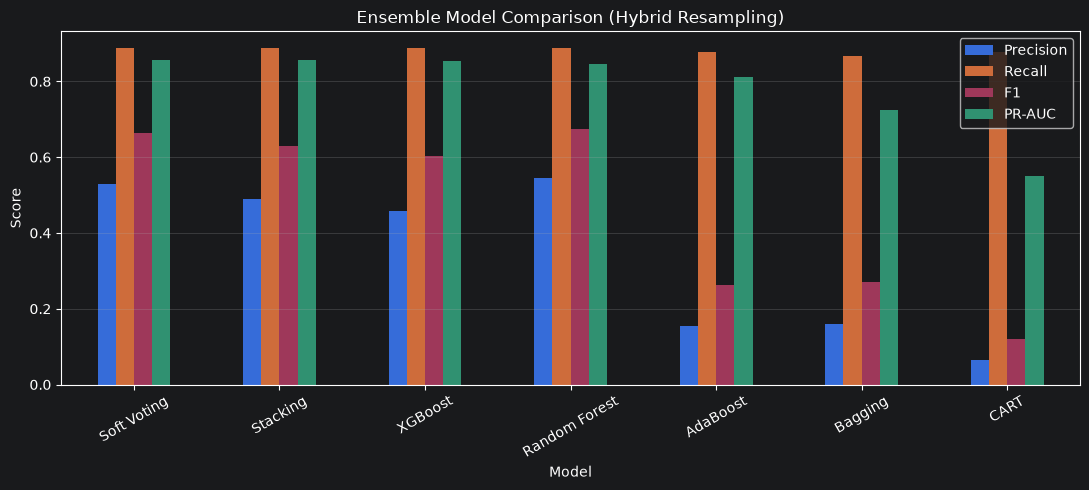

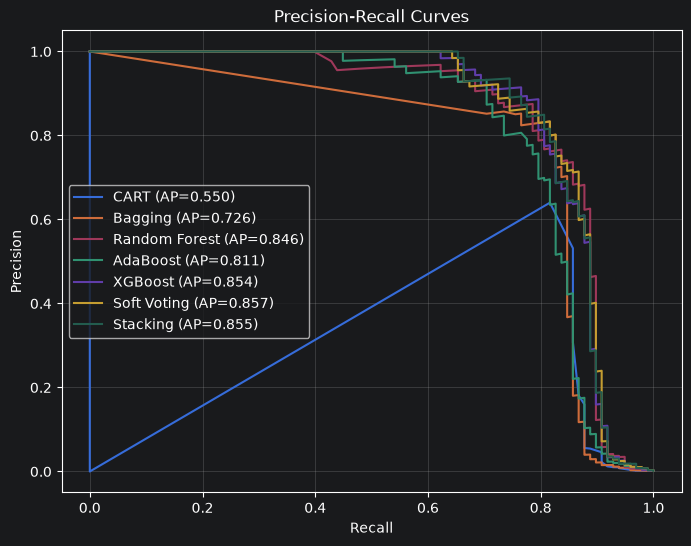

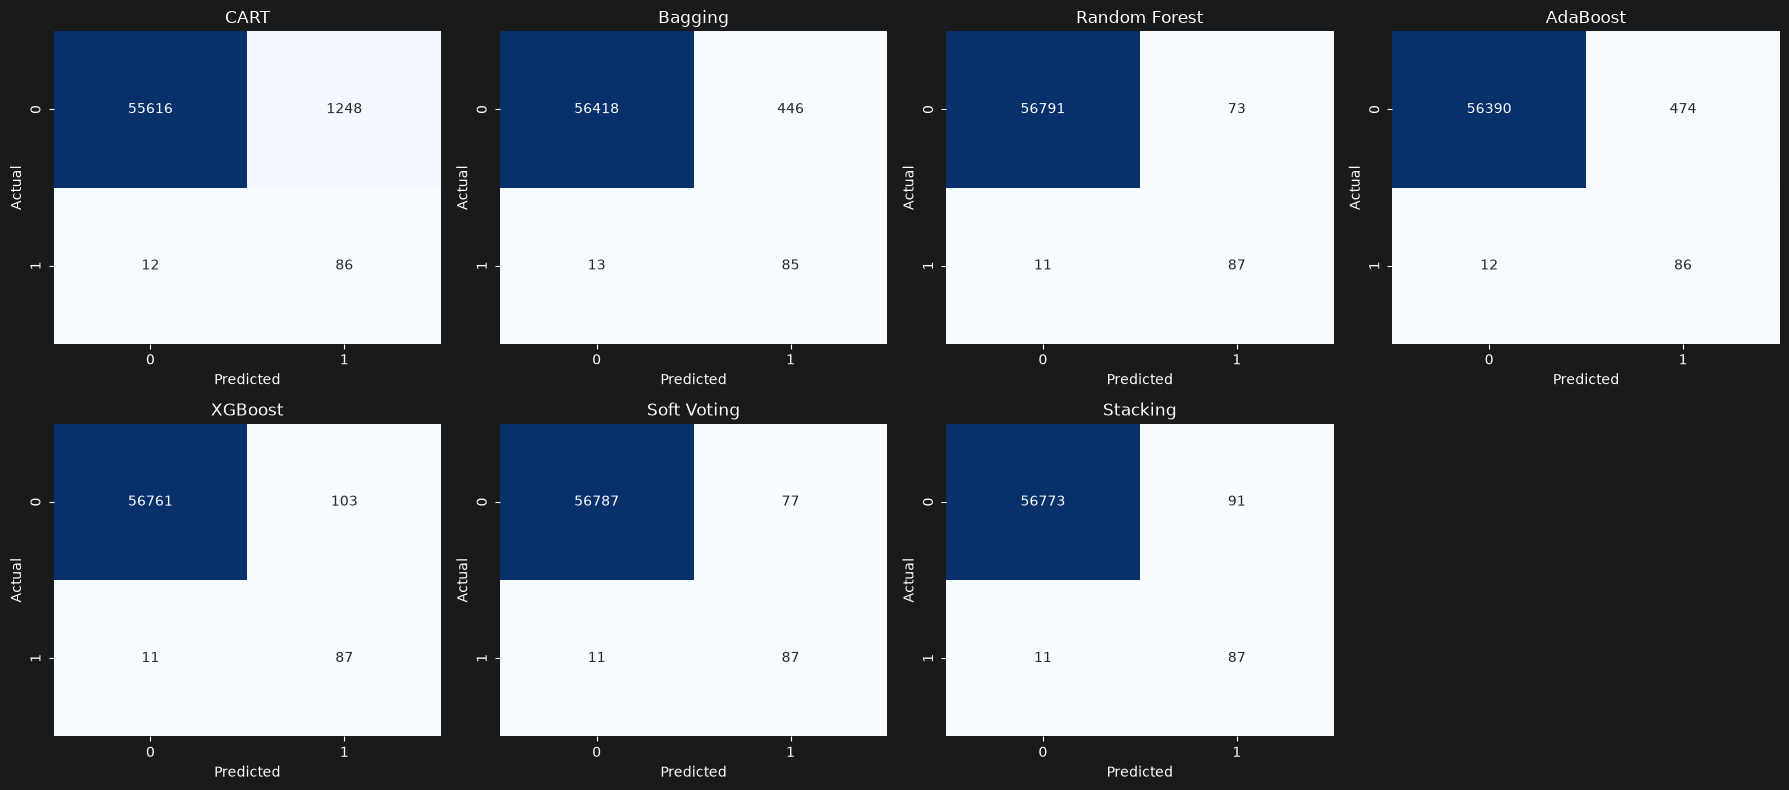

In [6]:
# 5a. Metric bar chart
results[["Precision", "Recall", "F1", "PR-AUC"]].plot(kind="bar", figsize=(11, 5))
plt.title("Ensemble Model Comparison (Hybrid Resampling)")
plt.ylabel("Score"); plt.xticks(rotation=30); plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

# 5b. Precision-Recall curves
from sklearn.metrics import precision_recall_curve
plt.figure(figsize=(8, 6))
for name, prob in probs.items():
    p, r, _ = precision_recall_curve(y_test, prob)
    plt.plot(r, p, label=f"{name} (AP={average_precision_score(y_test, prob):.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curves"); plt.legend(); plt.grid(alpha=.3); plt.show()

# 5c. Confusion matrices
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (name, pred) in zip(axes.ravel(), preds.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

## Step 6: Resampling strategy comparison (XGBoost only, to keep it fast)

This step isolates the effect of resampling by training the same XGBoost configuration on each strategy and comparing the resulting test metrics.

In [7]:
strat_rows = []
for s in ["None", "Undersampling", "SMOTE", "Hybrid (SMOTE+Under)"]:
    Xs, ys = get_resampled(s)
    m = XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                      eval_metric="logloss", n_jobs=-1, random_state=42).fit(Xs, ys)
    pred, prob = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    strat_rows.append({"Strategy": s,
                       "Precision": precision_score(y_test, pred),
                       "Recall": recall_score(y_test, pred),
                       "F1": f1_score(y_test, pred),
                       "PR-AUC": average_precision_score(y_test, prob)})
strat_df = pd.DataFrame(strat_rows).set_index("Strategy").round(4)
strat_df

,Precision,Recall,F1,PR-AUC
Strategy,,,,
None,0.9277,0.7857,0.8508,0.8412
Undersampling,0.4628,0.8878,0.6084,0.7571
SMOTE,0.7411,0.8469,0.7905,0.8638
Hybrid (SMOTE+Under),0.4579,0.8878,0.6042,0.8541


## Step 7: Feature importance from the best tree model

This step extracts the Random Forest feature-importance scores and displays the 15 features that contribute most to its predictions.

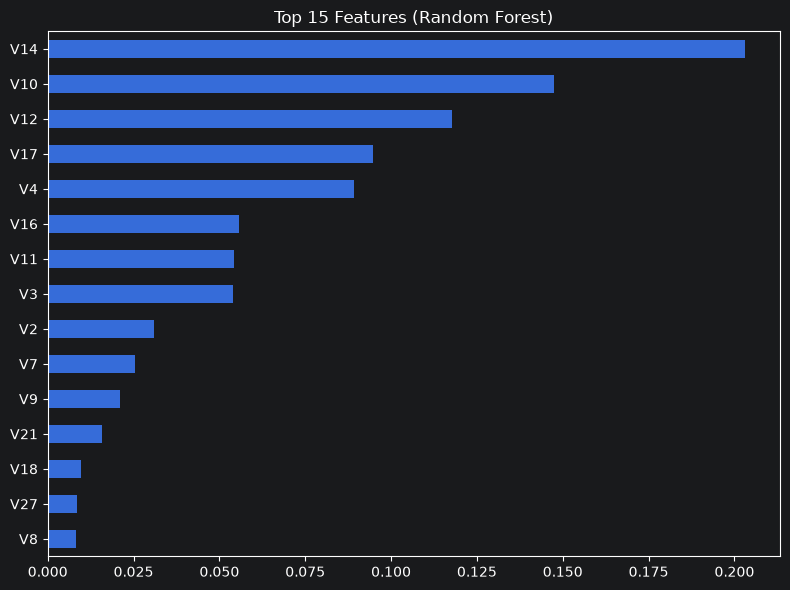

In [8]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=X_train.columns).sort_values()
imp.tail(15).plot(kind="barh", figsize=(8, 6), title="Top 15 Features (Random Forest)")
plt.tight_layout(); plt.show()

## Step 8: Save results for your slides and report

This step exports both comparison tables as CSV files so they can be reused in the presentation and technical report.

In [9]:
results.to_csv("ensemble_results.csv")
strat_df.to_csv("resampling_comparison.csv")

## Step 9: Interpretation (fill after you see your numbers)

Read your table and answer these four questions. They become your slide 6:

1. Which model has the highest **recall** (fraud caught) and which the highest **precision** (fewest false alarms)?
2. Did the boosting models (AdaBoost, XGBoost) beat the single CART? By how much?
3. Did voting or stacking improve over the best single model, or just match it?
4. In Step 6, how much did resampling improve recall vs. "None"?

Paste your two result tables (`results` and `strat_df`) here to write the interpretation paragraph and slide text.

## Notes so nothing breaks tomorrow

- **Runtime:** the full run should take roughly 5 to 15 minutes. Stacking is the slowest. If it is too slow, change `n_estimators=150` to `80` in RF and `200` to `100` in XGBoost.
- **Do not change the test set** or apply SMOTE to it.
- **Bayesian model averaging:** Soft Voting is your practical version of it. On the slide, say "it averages the predicted probabilities of several models, the same idea as Bayesian model averaging with equal weights."
- If `AdaBoostClassifier(estimator=...)` errors, your scikit-learn is old. Replace `estimator=` with `base_estimator=`.

Run it step by step, and paste any error or your results tables here.